<a href="https://colab.research.google.com/github/AnirudhRajesh09/BIS/blob/main/BIS_Pgm5_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Ground Truth Center: (132, 124), Radii: (28, 68)
Detected Pupil (x, y, r): (np.int64(132), np.int64(124), np.int32(28))
Detected Iris  (x, y, r): (np.int64(132), np.int64(124), np.int32(68))
GPU SL-PCHT Execution Time: 10.52 ms


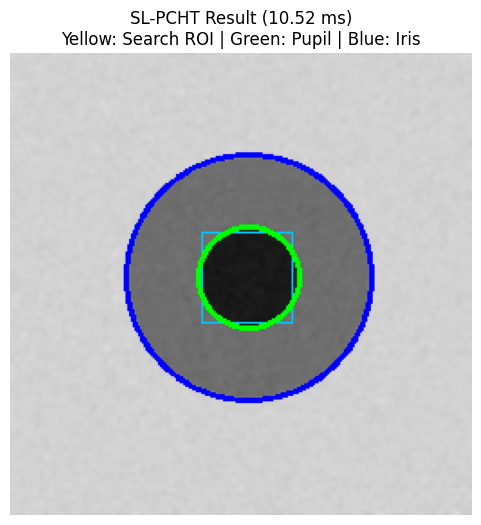

In [1]:
import math
import time
import cv2
import numpy as np
import matplotlib.pyplot as plt
from numba import cuda

# ---------------------------------------------------------
# 1. Generate Synthetic Eye Image (Pupil + Iris + Noise)
# ---------------------------------------------------------
def create_synthetic_eye(size=256):
    img = np.full((size, size), 210, dtype=np.uint8)  # Sclera background
    true_center = (132, 124)
    pupil_r = 28
    iris_r = 68

    # Draw outer iris and inner pupil
    cv2.circle(img, true_center, iris_r, 110, -1)
    cv2.circle(img, true_center, pupil_r, 25, -1)

    # Add realistic Gaussian noise & slight blur
    noise = np.random.normal(0, 8, img.shape).astype(np.int16)
    img = np.clip(img.astype(np.int16) + noise, 0, 255).astype(np.uint8)
    img = cv2.GaussianBlur(img, (5, 5), 1.2)
    return img, true_center, (pupil_r, iris_r)


# ---------------------------------------------------------
# 2. Search Localization (Coarse Center Estimation)
# ---------------------------------------------------------
def localize_search_window(gray_img, margin=25):
    # Threshold darkest pixels corresponding to the pupil
    _, binary_pupil = cv2.threshold(gray_img, 50, 255, cv2.THRESH_BINARY_INV)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    cleaned = cv2.morphologyEx(binary_pupil, cv2.MORPH_OPEN, kernel)

    moments = cv2.moments(cleaned)
    if moments["m00"] > 0:
        cx = int(moments["m10"] / moments["m00"])
        cy = int(moments["m01"] / moments["m00"])
    else:
        cy, cx = gray_img.shape[0] // 2, gray_img.shape[1] // 2

    x_min = max(0, cx - margin)
    x_max = min(gray_img.shape[1], cx + margin)
    y_min = max(0, cy - margin)
    y_max = min(gray_img.shape[0], cy + margin)
    return (x_min, x_max, y_min, y_max)


# ---------------------------------------------------------
# 3. CUDA Kernel: Parallel Circular Hough Voting
# ---------------------------------------------------------
@cuda.jit
def parallel_cht_kernel(edge_x, edge_y, radii, cos_table, sin_table,
                        x_min, x_max, y_min, y_max, acc):
    """
    Each thread processes one (edge_pixel, radius_index) pair and votes
    across all quantized angles theta in parallel using atomic additions.
    """
    idx = cuda.grid(1)
    num_edges = edge_x.shape[0]
    num_radii = radii.shape[0]

    if idx >= num_edges * num_radii:
        return

    e_idx = idx // num_radii
    r_idx = idx % num_radii

    x = edge_x[e_idx]
    y = edge_y[e_idx]
    r = radii[r_idx]

    num_angles = cos_table.shape[0]
    for t in range(num_angles):
        a = int(round(x - r * cos_table[t]))
        b = int(round(y - r * sin_table[t]))

        # Vote only if the candidate center lies inside the localized window
        if x_min <= a < x_max and y_min <= b < y_max:
            cuda.atomic.add(acc, (r_idx, b - y_min, a - x_min), 1)


# ---------------------------------------------------------
# 4. Host Pipeline Execution
# ---------------------------------------------------------
def detect_iris_gpu(img, r_min=20, r_max=80, num_angles=180):
    t0 = time.perf_counter()

    # Step A: Search Localization
    x_min, x_max, y_min, y_max = localize_search_window(img, margin=25)
    win_w = x_max - x_min
    win_h = y_max - y_min

    # Step B: Edge Extraction (Canny)
    edges = cv2.Canny(img, 50, 120)
    edge_y, edge_x = np.nonzero(edges)
    edge_x = edge_x.astype(np.int32)
    edge_y = edge_y.astype(np.int32)

    # Precompute trig lookup tables & radii
    radii = np.arange(r_min, r_max + 1, dtype=np.int32)
    angles = np.linspace(0, 2 * math.pi, num_angles, endpoint=False)
    cos_table = np.cos(angles).astype(np.float32)
    sin_table = np.sin(angles).astype(np.float32)

    # Allocate localized 3D accumulator on GPU
    d_edge_x = cuda.to_device(edge_x)
    d_edge_y = cuda.to_device(edge_y)
    d_radii = cuda.to_device(radii)
    d_cos = cuda.to_device(cos_table)
    d_sin = cuda.to_device(sin_table)
    d_acc = cuda.to_device(np.zeros((len(radii), win_h, win_w), dtype=np.int32))

    # Launch CUDA grid
    total_tasks = len(edge_x) * len(radii)
    threads_per_block = 256
    blocks_per_grid = (total_tasks + threads_per_block - 1) // threads_per_block

    parallel_cht_kernel[blocks_per_grid, threads_per_block](
        d_edge_x, d_edge_y, d_radii, d_cos, d_sin,
        x_min, x_max, y_min, y_max, d_acc
    )
    cuda.synchronize()
    acc = d_acc.copy_to_host()

    # Step C: Extract two peak circles (Pupil & Outer Iris)
    # Normalize votes by radius circumference so larger circles aren't biased
    norm_acc = acc / radii[:, None, None]

    # Peak 1: Inner pupil (smaller radius range)
    pupil_mask = radii < 45
    p_idx = np.unravel_index(np.argmax(norm_acc[pupil_mask]), norm_acc[pupil_mask].shape)
    pupil_circle = (p_idx[2] + x_min, p_idx[1] + y_min, radii[pupil_mask][p_idx[0]])

    # Peak 2: Outer iris (larger radius range)
    iris_mask = radii >= 45
    i_idx = np.unravel_index(np.argmax(norm_acc[iris_mask]), norm_acc[iris_mask].shape)
    iris_circle = (i_idx[2] + x_min, i_idx[1] + y_min, radii[iris_mask][i_idx[0]])

    elapsed_ms = (time.perf_counter() - t0) * 1000
    return pupil_circle, iris_circle, (x_min, y_min, win_w, win_h), elapsed_ms


# ---------------------------------------------------------
# 5. Run & Visualize Results
# ---------------------------------------------------------
if __name__ == "__main__":
    if not cuda.is_available():
        raise RuntimeError("CUDA GPU not detected. Enable GPU in Colab: Runtime -> Change runtime type -> T4 GPU.")

    eye_img, gt_center, gt_radii = create_synthetic_eye()
    # Warmup JIT compilation
    _ = detect_iris_gpu(eye_img)

    # Timed run
    pupil, iris, roi, runtime_ms = detect_iris_gpu(eye_img)

    print(f"Ground Truth Center: {gt_center}, Radii: {gt_radii}")
    print(f"Detected Pupil (x, y, r): {pupil}")
    print(f"Detected Iris  (x, y, r): {iris}")
    print(f"GPU SL-PCHT Execution Time: {runtime_ms:.2f} ms")

    # Plot detection overlay
    vis = cv2.cvtColor(eye_img, cv2.COLOR_GRAY2BGR)
    cv2.rectangle(vis, (roi[0], roi[1]), (roi[0] + roi[2], roi[1] + roi[3]), (255, 200, 0), 1)
    cv2.circle(vis, (pupil[0], pupil[1]), pupil[2], (0, 255, 0), 2)
    cv2.circle(vis, (iris[0], iris[1]), iris[2], (255, 0, 0), 2)

    plt.figure(figsize=(6, 6))
    plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    plt.title(f"SL-PCHT Result ({runtime_ms:.2f} ms)\nYellow: Search ROI | Green: Pupil | Blue: Iris")
    plt.axis("off")
    plt.show()

Data Cleaning (Figure 1): Retained 1386/2500 valid charging events.

Training baseline ML models (ELM, FFNN, SVR)...
Running Grey Wolf Optimization (GWO) for hyperparameter tuning...

=== Model Evaluation Comparison on Test Set (Table 6 Format) ===
            RMSE   MAPE    RSR     R2    WIA   NSEC
ELM       16.974  0.080  0.263  0.931  0.982  0.745
FFNN      15.679  0.076  0.243  0.941  0.985  0.758
SVR       16.222  0.078  0.252  0.937  0.984  0.750
GWO-ELM   16.249  0.078  0.252  0.936  0.984  0.749
GWO-FFNN  15.578  0.075  0.242  0.942  0.985  0.759
GWO-SVR   16.593  0.078  0.257  0.934  0.983  0.750


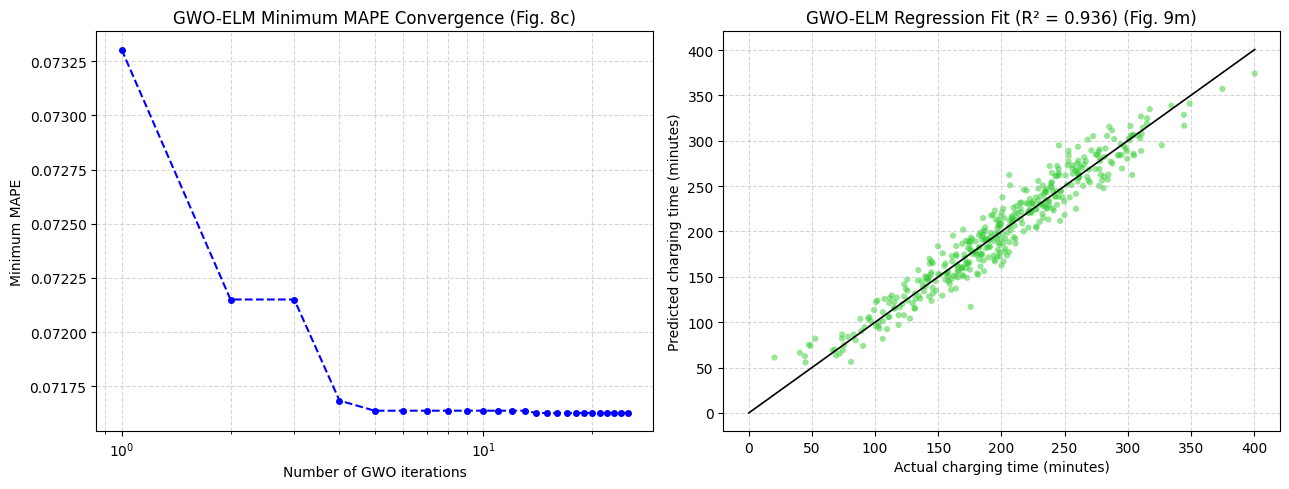


Computing SHAP feature importance values (Section 6)...


  0%|          | 0/100 [00:00<?, ?it/s]

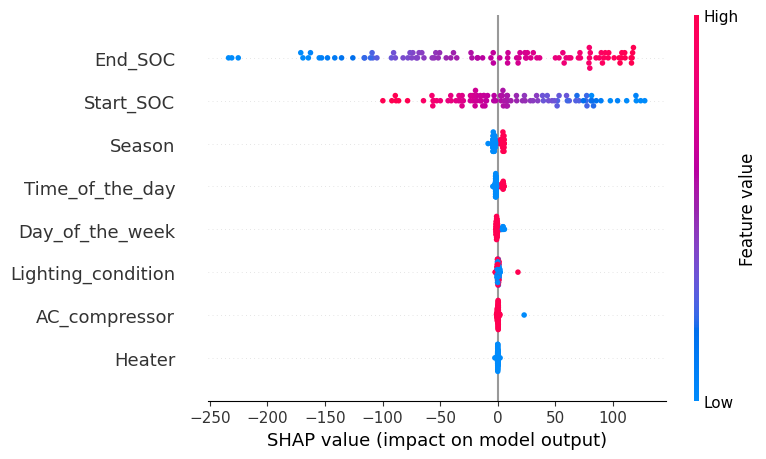

In [2]:
# Install SHAP if running in Google Colab
try:
    import shap
except ImportError:
    !pip install -q shap
    import shap

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score

# Set random seed for reproducibility
np.random.seed(42)

# ==============================================================================
# 1. DATA GENERATION & PREPROCESSING (Section 3, Table 2 & Figure 1)
# ==============================================================================
def generate_ev_dataset(n_samples=3000):
    """
    Generates synthetic EV charging event data matching the statistical
    properties in Table 2 and Figure 2 of the paper.
    Note: Original study used 100,556 cleaned events; scaled to 3,000 here
    so GWO metaheuristic optimization runs quickly in Colab.
    """
    # Explanatory variables matching Table 2 means/SDs (encoded as 1 or 2)
    lighting = np.random.choice([1, 2], size=n_samples, p=[0.631, 0.369])   # Mean ~1.37
    time_of_day = np.random.choice([1, 2], size=n_samples, p=[0.740, 0.260]) # Mean ~1.26
    day_of_week = np.random.choice([1, 2], size=n_samples, p=[0.179, 0.821]) # Mean ~1.82
    season = np.random.choice([1, 2], size=n_samples, p=[0.530, 0.470])      # Mean ~1.47
    ac_comp = np.random.choice([1, 2], size=n_samples, p=[0.019, 0.981])     # Mean ~1.98
    heater = np.random.choice([1, 2], size=n_samples, p=[0.014, 0.986])      # Mean ~1.99

    start_soc = np.clip(np.random.normal(61.057, 21.660, n_samples), -2, 98)
    end_soc = np.clip(start_soc + np.random.normal(33.2, 15.0, n_samples), 5, 102)

    # Nonlinear charging time relationship reflecting paper's SHAP & correlation insights
    delta_soc = np.maximum(end_soc - start_soc, 0.5)
    base_time = (
        3.2 * delta_soc
        + 0.015 * (end_soc ** 2)
        + 12.0 * (ac_comp - 1)
        + 8.0 * (season - 1)
        + 5.0 * (time_of_day - 1)
        - 4.0 * (day_of_week - 1)
        + np.random.normal(0, 15, n_samples)
    )
    charging_time = np.maximum(base_time, 1.0)

    df = pd.DataFrame({
        "Lighting_condition": lighting,
        "Time_of_the_day": time_of_day,
        "Day_of_the_week": day_of_week,
        "Season": season,
        "AC_compressor": ac_comp,
        "Heater": heater,
        "Start_SOC": start_soc,
        "End_SOC": end_soc,
        "Charging_time": charging_time
    })
    return df


def preprocess_data(df):
    """
    Implements Figure 1 (Data Elimination rules) & Section 3 (Min-Max Normalization
    to [0, 1] and Log transformation for skewed charging time).
    """
    initial_count = len(df)

    # Figure 1: Eliminate invalid SOC bounds (<0% or >100%)
    df = df[(df["Start_SOC"] >= 0) & (df["End_SOC"] <= 100)]

    # Figure 1: Eliminate SOC difference < 1% or charging duration < 2 minutes
    df = df[(df["End_SOC"] - df["Start_SOC"] >= 1.0) & (df["Charging_time"] >= 2.0)]
    df = df.reset_index(drop=True)

    print(f"Data Cleaning (Figure 1): Retained {len(df)}/{initial_count} valid charging events.")

    feature_cols = [
        "Lighting_condition", "Time_of_the_day", "Day_of_the_week",
        "Season", "AC_compressor", "Heater", "Start_SOC", "End_SOC"
    ]
    X = df[feature_cols].values
    y_raw = df["Charging_time"].values

    # Section 3 (Figure 3d): Log transformation to normalize right-skewed response
    y_log = np.log(y_raw)

    # Section 5.1: Random split 70% Training, 30% Testing
    X_train, X_test, y_train_log, y_test_log, y_train_raw, y_test_raw = train_test_split(
        X, y_log, y_raw, test_size=0.30, random_state=42
    )

    # Section 3 & 4.3: Normalize input features to [0.0, 1.0]
    scaler = MinMaxScaler(feature_range=(0, 1))
    X_train_norm = scaler.fit_transform(X_train)
    X_test_norm = scaler.transform(X_test)

    return X_train_norm, X_test_norm, y_train_log, y_test_log, y_train_raw, y_test_raw, feature_cols


# ==============================================================================
# 2. EVALUATION METRICS (Section 4.4, Table 3)
# ==============================================================================
def evaluate_metrics(y_true, y_pred):
    """
    Computes the 6 exact evaluation metrics defined in Table 3:
    RMSE, MAPE, RSR, R2, WIA, and NSEC.
    """
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()
    y_mean = np.mean(y_true)

    # 1. Root Mean Square Error (RMSE)
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))

    # 2. Mean Absolute Percentage Error (MAPE) - expressed as ratio/decimal per Tables 5 & 6
    mape = np.mean(np.abs((y_true - y_pred) / np.maximum(np.abs(y_true), 1e-8)))

    # 3. RMSE Observation Standard Deviation Ratio (RSR)
    rsr = np.sqrt(np.sum((y_true - y_pred) ** 2) / np.sum((y_true - y_mean) ** 2))

    # 4. Coefficient of Determination (R2)
    r2 = 1.0 - (np.sum((y_true - y_pred) ** 2) / np.sum((y_true - y_mean) ** 2))

    # 5. Willmott Index of Agreement (WIA)
    num_wia = np.sum((y_true - y_pred) ** 2)
    den_wia = np.sum((np.abs(y_pred - y_mean) + np.abs(y_true - y_mean)) ** 2)
    wia = 1.0 - (num_wia / den_wia)

    # 6. Nash-Sutcliffe Model Efficiency Coefficient (NSEC - Table 3 formulation)
    nsec = 1.0 - (np.sum(np.abs(y_true - y_pred)) / np.sum(np.abs(y_true - y_mean)))

    return {
        "RMSE": round(rmse, 3),
        "MAPE": round(mape, 3),
        "RSR": round(rsr, 3),
        "R2": round(r2, 3),
        "WIA": round(wia, 3),
        "NSEC": round(nsec, 3)
    }


# ==============================================================================
# 3. MACHINE LEARNING MODELS (Sections 4.2, 4.3 & Table 4)
# ==============================================================================
class KernelELM:
    """
    Extreme Learning Machine (Section 4.2, Eqs. 13-16) with RBF kernel
    and regularization coefficient C (Table 4).
    """
    def __init__(self, C=5e6, gamma=1.0 / (2 * (5e4 ** 2))):
        self.C = C
        self.gamma = gamma

    def _rbf_kernel(self, X1, X2):
        sq_dists = (
            np.sum(X1 ** 2, axis=1).reshape(-1, 1)
            + np.sum(X2 ** 2, axis=1)
            - 2 * np.dot(X1, X2.T)
        )
        return np.exp(-self.gamma * np.maximum(sq_dists, 0))

    def fit(self, X, y):
        self.X_train = X
        n = X.shape[0]
        Omega = self._rbf_kernel(X, X)
        # Regularized Moore-Penrose analytical solution: (Omega + I/C)^(-1) * Y
        self.beta = np.linalg.solve(Omega + np.eye(n) / self.C, y)
        return self

    def predict(self, X):
        K = self._rbf_kernel(X, self.X_train)
        return np.dot(K, self.beta)


def build_ffnn(hidden_neurons=14, lr_init=0.01, alpha=0.0001):
    """
    Feed-Forward Neural Network (Section 4.3, Eq. 17) with tanh activation
    and optimal 14 hidden neurons (Section 5.2, Table 5).
    """
    return MLPRegressor(
        hidden_layer_sizes=(int(hidden_neurons),),
        activation="tanh",
        solver="lbfgs",
        alpha=alpha,
        max_iter=300,
        random_state=42
    )


def build_svr(C=1000.0, gamma=0.0095, epsilon=1.75e-7):
    """
    Support Vector Regression with RBF kernel (Table 4 parameters).
    """
    return SVR(kernel="rbf", C=C, gamma=gamma, epsilon=epsilon)


# ==============================================================================
# 4. GREY WOLF OPTIMIZER (Section 4.1, Eqs. 1-12)
# ==============================================================================
class GreyWolfOptimizer:
    """
    Implements GWO metaheuristic (Equations 1-12, Figure 4 & Figure 5)
    to minimize fitness (MAPE) over continuous hyperparameter bounds.
    """
    def __init__(self, obj_func, lb, ub, n_wolves=15, max_iter=30):
        # Note: Paper uses n_wolves=40, max_iter=300 (Table 4).
        # Scaled defaults (15 wolves, 30 iters) run in ~10s on Colab; increase as needed.
        self.obj_func = obj_func
        self.lb = np.array(lb, dtype=float)
        self.ub = np.array(ub, dtype=float)
        self.dim = len(lb)
        self.n_wolves = n_wolves
        self.max_iter = max_iter

    def optimize(self):
        # Initialize wolf pack positions within bounds
        positions = np.random.uniform(self.lb, self.ub, (self.n_wolves, self.dim))

        alpha_pos = np.zeros(self.dim)
        alpha_score = float("inf")
        beta_pos = np.zeros(self.dim)
        beta_score = float("inf")
        delta_pos = np.zeros(self.dim)
        delta_score = float("inf")

        min_mape_curve = []
        mean_mape_curve = []

        for t in range(self.max_iter):
            iter_scores = []
            for i in range(self.n_wolves):
                # Clamp positions to search boundaries
                positions[i] = np.clip(positions[i], self.lb, self.ub)
                fitness = self.obj_func(positions[i])
                iter_scores.append(fitness)

                # Update Alpha, Beta, and Delta hierarchy (Figure 4)
                if fitness < alpha_score:
                    delta_score, delta_pos = beta_score, beta_pos.copy()
                    beta_score, beta_pos = alpha_score, alpha_pos.copy()
                    alpha_score, alpha_pos = fitness, positions[i].copy()
                elif fitness < beta_score:
                    delta_score, delta_pos = beta_score, beta_pos.copy()
                    beta_score, beta_pos = fitness, positions[i].copy()
                elif fitness < delta_score:
                    delta_score, delta_pos = fitness, positions[i].copy()

            min_mape_curve.append(alpha_score)
            mean_mape_curve.append(np.mean(iter_scores))

            # Eq. (5): a decreases linearly from 2 to 0
            a = 2.0 - t * (2.0 / self.max_iter)

            # Update position of each Omega wolf (Eqs. 3-4, 6-12)
            for i in range(self.n_wolves):
                for d in range(self.dim):
                    # Alpha guidance (Eqs. 6 & 9)
                    r1, r2 = np.random.rand(), np.random.rand()
                    A1 = 2 * a * r1 - a
                    C1 = 2 * r2
                    D_alpha = abs(C1 * alpha_pos[d] - positions[i, d])
                    X1 = alpha_pos[d] - A1 * D_alpha

                    # Beta guidance (Eqs. 7 & 10)
                    r1, r2 = np.random.rand(), np.random.rand()
                    A2 = 2 * a * r1 - a
                    C2 = 2 * r2
                    D_beta = abs(C2 * beta_pos[d] - positions[i, d])
                    X2 = beta_pos[d] - A2 * D_beta

                    # Delta guidance (Eqs. 8 & 11)
                    r1, r2 = np.random.rand(), np.random.rand()
                    A3 = 2 * a * r1 - a
                    C3 = 2 * r2
                    D_delta = abs(C3 * delta_pos[d] - positions[i, d])
                    X3 = delta_pos[d] - A3 * D_delta

                    # Eq. (12): Equal weight average of top three wolves
                    positions[i, d] = (X1 + X2 + X3) / 3.0

        return alpha_pos, alpha_score, min_mape_curve, mean_mape_curve


# ==============================================================================
# 5. MAIN EXECUTION PIPELINE (Figure 7 Workflow)
# ==============================================================================
if __name__ == "__main__":
    # Step 1: Load and preprocess data
    raw_df = generate_ev_dataset(n_samples=2500)
    X_train, X_test, y_train_log, y_test_log, y_train_raw, y_test_raw, feature_names = preprocess_data(raw_df)

    # Split a validation subset from training data for GWO hyperparameter fitness evaluation
    X_tr, X_val, y_tr_log, y_val_log, _, y_val_raw = train_test_split(
        X_train, y_train_log, y_train_raw, test_size=0.2, random_state=42
    )

    results = {}

    # --------------------------------------------------------------------------
    # Step 2: Baseline Models (Table 4 initial parameters)
    # --------------------------------------------------------------------------
    print("\nTraining baseline ML models (ELM, FFNN, SVR)...")
    elm_base = KernelELM(C=1e3, gamma=0.5).fit(X_train, y_train_log)
    results["ELM"] = evaluate_metrics(y_test_raw, np.exp(elm_base.predict(X_test)))

    ffnn_base = build_ffnn(hidden_neurons=14, alpha=0.01).fit(X_train, y_train_log)
    results["FFNN"] = evaluate_metrics(y_test_raw, np.exp(ffnn_base.predict(X_test)))

    svr_base = build_svr(C=100.0, gamma=0.1, epsilon=0.01).fit(X_train, y_train_log)
    results["SVR"] = evaluate_metrics(y_test_raw, np.exp(svr_base.predict(X_test)))

    # --------------------------------------------------------------------------
    # Step 3: GWO-Optimized Models (GWO-ELM, GWO-FFNN, GWO-SVR)
    # --------------------------------------------------------------------------
    print("Running Grey Wolf Optimization (GWO) for hyperparameter tuning...")

    # 3a. Optimize GWO-ELM (tuning log10(C) and log10(gamma))
    def elm_fitness(params):
        C_val = 10 ** params[0]
        gamma_val = 10 ** params[1]
        model = KernelELM(C=C_val, gamma=gamma_val).fit(X_tr, y_tr_log)
        preds = np.exp(model.predict(X_val))
        return np.mean(np.abs((y_val_raw - preds) / y_val_raw))

    gwo_elm = GreyWolfOptimizer(elm_fitness, lb=[0, -3], ub=[6, 1], n_wolves=12, max_iter=25)
    best_elm_params, _, elm_min_curve, elm_mean_curve = gwo_elm.optimize()
    gwo_elm_model = KernelELM(C=10**best_elm_params[0], gamma=10**best_elm_params[1]).fit(X_train, y_train_log)
    gwo_elm_preds = np.exp(gwo_elm_model.predict(X_test))
    results["GWO-ELM"] = evaluate_metrics(y_test_raw, gwo_elm_preds)

    # 3b. Optimize GWO-FFNN (tuning hidden neurons [2..15] and log10(alpha))
    def ffnn_fitness(params):
        neurons = int(round(params[0]))
        alpha_val = 10 ** params[1]
        model = build_ffnn(hidden_neurons=neurons, alpha=alpha_val).fit(X_tr, y_tr_log)
        preds = np.exp(model.predict(X_val))
        return np.mean(np.abs((y_val_raw - preds) / y_val_raw))

    gwo_ffnn = GreyWolfOptimizer(ffnn_fitness, lb=[2, -5], ub=[15, 0], n_wolves=10, max_iter=20)
    best_ffnn_params, _, ffnn_min_curve, ffnn_mean_curve = gwo_ffnn.optimize()
    gwo_ffnn_model = build_ffnn(
        hidden_neurons=int(round(best_ffnn_params[0])), alpha=10**best_ffnn_params[1]
    ).fit(X_train, y_train_log)
    gwo_ffnn_preds = np.exp(gwo_ffnn_model.predict(X_test))
    results["GWO-FFNN"] = evaluate_metrics(y_test_raw, gwo_ffnn_preds)

    # 3c. Optimize GWO-SVR (tuning log10(C), log10(gamma), log10(epsilon))
    def svr_fitness(params):
        model = build_svr(
            C=10**params[0], gamma=10**params[1], epsilon=10**params[2]
        ).fit(X_tr, y_tr_log)
        preds = np.exp(model.predict(X_val))
        return np.mean(np.abs((y_val_raw - preds) / y_val_raw))

    gwo_svr = GreyWolfOptimizer(svr_fitness, lb=[0, -3, -5], ub=[3, 0, -1], n_wolves=10, max_iter=20)
    best_svr_params, _, _, _ = gwo_svr.optimize()
    gwo_svr_model = build_svr(
        C=10**best_svr_params[0], gamma=10**best_svr_params[1], epsilon=10**best_svr_params[2]
    ).fit(X_train, y_train_log)
    gwo_svr_preds = np.exp(gwo_svr_model.predict(X_test))
    results["GWO-SVR"] = evaluate_metrics(y_test_raw, gwo_svr_preds)

    # --------------------------------------------------------------------------
    # Step 4: Display Comparative Results Table (Analogous to Table 6)
    # --------------------------------------------------------------------------
    results_df = pd.DataFrame(results).T
    print("\n=== Model Evaluation Comparison on Test Set (Table 6 Format) ===")
    print(results_df.to_string())

    # --------------------------------------------------------------------------
    # Step 5: Plot GWO Convergence & Actual vs. Predicted Scatter (Figs. 8 & 9)
    # --------------------------------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # GWO-ELM Minimum MAPE Convergence (Figure 8c)
    axes[0].plot(range(1, len(elm_min_curve) + 1), elm_min_curve, "b--o", markersize=4)
    axes[0].set_xscale("log")
    axes[0].set_xlabel("Number of GWO iterations")
    axes[0].set_ylabel("Minimum MAPE")
    axes[0].set_title("GWO-ELM Minimum MAPE Convergence (Fig. 8c)")
    axes[0].grid(True, which="both", linestyle="--", alpha=0.5)

    # Actual vs. Predicted Charging Time for GWO-ELM (Figure 9m)
    axes[1].scatter(y_test_raw, gwo_elm_preds, color="limegreen", alpha=0.5, edgecolors="none", s=20)
    max_val = max(y_test_raw.max(), gwo_elm_preds.max())
    axes[1].plot([0, max_val], [0, max_val], "k-", linewidth=1.2)
    axes[1].set_xlabel("Actual charging time (minutes)")
    axes[1].set_ylabel("Predicted charging time (minutes)")
    axes[1].set_title(f"GWO-ELM Regression Fit (R² = {results['GWO-ELM']['R2']}) (Fig. 9m)")
    axes[1].grid(True, linestyle="--", alpha=0.5)

    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------------------------
    # Step 6: SHAP Explainability Analysis (Section 6, Figures 10 & 11)
    # --------------------------------------------------------------------------
    print("\nComputing SHAP feature importance values (Section 6)...")
    background = shap.kmeans(X_train, 25)
    explainer = shap.KernelExplainer(lambda x: np.exp(gwo_elm_model.predict(x)), background)
    shap_values = explainer.shap_values(X_test[:100], nsamples=100)

    plt.figure(figsize=(8, 5))
    shap.summary_plot(shap_values, X_test[:100], feature_names=feature_names, show=True)